# Chunk 46 — S11 prediction figures (figures only)

**Ten figures, all from test antennas:**

| grid | curves | figures |
|---|---|---|
| **25×25** | ground truth + prediction after replay-based fine-tuning | single band, dual band |
| **12×12, 15×15, 35×35, 45×45** | ground truth + zero-shot (trained on 25×25 only) + prediction after replay-based fine-tuning | single band, dual band for each (8 figures) |

55×55 is excluded.

**Models:**
- **"After replay-based fine-tuning":** the Chunk 44 five-grid model `ch44_ft15_from4_replay_p100_s0.pt`, one network for all five grids. Edit `MODEL_FT` in cell 3 to plot another checkpoint.
- **"Zero-shot":** `best_model.pt`, trained on 25×25 only.

**Band definition, pre-registered:** count the true curve's dips below −10 dB that have ≥ 3 dB prominence and are ≥ 150 MHz apart. One dip is single band; two is dual band.

**Example selection: the most accurate prediction.** Within each grid and band type, the figure shows the test antenna whose **fine-tuned prediction has the lowest error**. MSE is used by default; set `SELECT_METRIC = 'mae'` in cell 3 to rank by MAE instead. These are **best-case examples**, so to keep the figures honest:
- every caption says the example is the most accurate of N such test antennas
- every caption also gives that group's **median** error
- `ch46_selected_examples.csv` records the best and median errors side by side

**Harness:** before anything is plotted, both models' test MSE on every grid must reproduce Chunk 44's recorded values.

**Rules:** no training, and no model or threshold choices made on test data.

**Writes:**
- `figures/ch46/ch46_{N}x{N}_{single|dual}_band.{pdf,png}`: IEEE single-column 3.5 in, Times-compatible serif, vector PDF with embedded fonts, plus a 600-dpi PNG
- `ch46_selected_examples.csv`, `ch46_band_counts.csv`, `ch46_captions.md`

## 1. Installs

In [ ]:
!apt-get -qq install -y fonts-liberation > /dev/null 2>&1
!pip -q install torch_geometric pyarrow tabulate

## 2. Repository and Drive

In [ ]:
import os, sys, subprocess
REPO_ROOT = '/content/antenna_gnn'
if os.path.isdir(f'{REPO_ROOT}/.git'):
    subprocess.run(['git', '-C', REPO_ROOT, 'pull', '-q'], check=True)
else:
    subprocess.run(['git', 'clone', '-q', 'https://github.com/asparagusD/antenna_gnn.git', REPO_ROOT], check=True)
sys.path.insert(0, f'{REPO_ROOT}/src')
from google.colab import drive
drive.mount('/content/drive')
DATA_ROOT = '/content/drive/MyDrive/antenna_gnn'
ART, CKPT, SPLITS, LOCAL = f'{DATA_ROOT}/artifacts', f'{DATA_ROOT}/checkpoints', f'{DATA_ROOT}/splits', '/content/local_graphs'
os.makedirs(LOCAL, exist_ok=True)
print(REPO_ROOT, DATA_ROOT)

Mounted at /content/drive
/content/antenna_gnn /content/drive/MyDrive/antenna_gnn


## 3. Setup
**What it sets:**
- the two model checkpoints
- the band and selection rules
- the output folder
- the figure style: 8 pt Times-compatible serif, and a colour-blind-safe palette that also reads in grayscale through line styles — black solid for ground truth, orange dotted for zero-shot, blue dashed for fine-tuned

In [ ]:
# ── Setup: models to plot, selection rule, figure style ──
import json, glob, hashlib, zipfile, shutil
from pathlib import Path
import numpy as np, pandas as pd, torch
from scipy.signal import find_peaks
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as GeoLoader
import matplotlib, matplotlib.pyplot as plt
from matplotlib import font_manager
from tqdm.auto import tqdm
from model import AntennaGNN
from feed_component import AppendFeedComponentFeature

# Models. "Fine-tuned" = the replay-fine-tuned five-grid model (Chunk 44), the single network that serves
# 12/15/25/35/45. "Zero-shot" = best_model, trained on 25x25 only. Change MODEL_FT to plot another checkpoint.
MODEL_FT = f'{CKPT}/ch44_ft15_from4_replay_p100_s0.pt'; FT_ID = 'ft15_from4_replay_p100_s0'
MODEL_ZS = f'{CKPT}/best_model.pt'
GRIDS = (25, 12, 15, 35, 45)
F = np.linspace(1, 4, 201); TAU = -10.0
# Band counting (pre-registered): a band is a dip of the TRUE curve below -10 dB, found as a local minimum with
# >= 3 dB prominence, at least 10 points (150 MHz) from the next. Single band = exactly 1, dual band = exactly 2.
BAND = dict(height=10.0, prominence=3.0, distance=10)
# Example selection: within each grid x band type, the test antenna with the MOST ACCURATE fine-tuned prediction
# (lowest per-sample error, by SELECT_METRIC). These are best-case examples; every caption says so and also reports the
# group's median error, so readers see both the best case and the typical case.
SELECT_METRIC = 'mse'          # 'mse' (dB²) or 'mae' (dB): the error used to rank predictions

FIG = f'{DATA_ROOT}/figures/ch46'; os.makedirs(FIG, exist_ok=True)
def OUT(n):
    assert n.startswith('ch46_'), n; return f'{ART}/{n}'
def sha(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(1 << 20), b''):
            h.update(b)
    return h.hexdigest()
PRIOR = {p: os.path.getmtime(p) for pat in (f'{ART}/*', f'{CKPT}/*.pt') for p in glob.glob(pat)
         if os.path.isfile(p) and not Path(p).name.startswith('ch46_')}
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
MEAN = torch.tensor(np.load(f'{ART}/s11_mean.npy'), dtype=torch.float32, device=DEVICE)   # read only
STD = torch.tensor(np.load(f'{ART}/s11_std.npy'), dtype=torch.float32, device=DEVICE)

# IEEE single-column style: 3.5 in wide, Times-compatible serif at 8 pt, vector PDF with embedded fonts + 600-dpi PNG
FONT = next((f for f in ('Times New Roman', 'Liberation Serif', 'DejaVu Serif')
             if any(f == x.name for x in font_manager.fontManager.ttflist)), 'serif')
matplotlib.rcParams.update({'font.family': 'serif', 'font.serif': [FONT], 'font.size': 8, 'axes.labelsize': 8,
                            'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 7, 'axes.linewidth': 0.6,
                            'axes.grid': True, 'grid.alpha': 0.3, 'grid.linewidth': 0.5, 'pdf.fonttype': 42,
                            'ps.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02, 'mathtext.fontset': 'stix'})
STYLE = {'gt': dict(color='#000000', lw=1.3, ls='-', label='Ground truth'),
         'zs': dict(color='#E69F00', lw=1.1, ls=':', label='Zero-shot (trained on 25×25 only)'),
         'ft': dict(color='#0072B2', lw=1.1, ls='--', label='Prediction after replay-based fine-tuning')}
print('font:', FONT, '| figures ->', FIG)

font: Liberation Serif | figures -> /content/drive/MyDrive/antenna_gnn/figures/ch46


## 4. Test sets and graphs
Loads the test splits for the five grids (25×25 from `indices.json`; 35/45 from the fine-tune files; 12/15 from `finetune12/15`) and stages the processed graphs.

In [ ]:
# ── Test splits and graphs ──
def pairs(v):
    if isinstance(v, dict):
        return {(int(g), int(i)) for g, x in v.items() for i in x}
    return {(int(e[0]), int(e[1])) for e in v}
TEST = {25: sorted(i for g, i in pairs(json.load(open(f'{SPLITS}/indices.json'))['test']) if g == 25)}
ft = pairs(json.load(open(f'{SPLITS}/finetune_test_indices.json')))
for N in (35, 45):
    TEST[N] = sorted(i for g, i in ft if g == N)
for N in (12, 15):
    TEST[N] = sorted(i for g, i in pairs(json.load(open(f'{SPLITS}/finetune{N}_test_indices.json'))))
for N in GRIDS:
    d = f'{LOCAL}/{N}x{N}'
    if not os.path.exists(f'{d}/_STAGED.txt'):
        os.makedirs(d, exist_ok=True)
        with zipfile.ZipFile(f'{DATA_ROOT}/data/processed/processed_{N}x{N}.zip') as Z:
            mem = [m for m in Z.namelist() if m.endswith('.pt')]
            for m in tqdm(mem, desc=f'stage {N}x{N}', leave=False):
                with Z.open(m) as a, open(f'{d}/{os.path.basename(m)}', 'wb') as b:
                    shutil.copyfileobj(a, b)
        open(f'{d}/_STAGED.txt', 'w').write(str(len(mem)))
    print(f'{N}x{N}: {len(TEST[N]):,} test antennas')
TRANSFORM = AppendFeedComponentFeature()
def load(N, i):
    d = torch.load(f'{LOCAL}/{N}x{N}/sample_{int(i)}.pt', weights_only=False)
    assert d.x.shape == (N * N + 1, 5) and float(d.x[-1, 3]) == -1.0 and d.y.numel() == 201
    return d

stage 25x25:   0%|          | 0/99833 [00:00<?, ?it/s]

25x25: 9,983 test antennas


stage 12x12:   0%|          | 0/7000 [00:00<?, ?it/s]

12x12: 700 test antennas


stage 15x15:   0%|          | 0/6367 [00:00<?, ?it/s]

15x15: 637 test antennas


stage 35x35:   0%|          | 0/4988 [00:00<?, ?it/s]

35x35: 499 test antennas


stage 45x45:   0%|          | 0/6984 [00:00<?, ?it/s]

45x45: 699 test antennas


## 5. Predictions and harness
**What it does:**
- Runs both models on every test antenna of every grid, in raw dB.
- Adds the feed-component feature for the 6-input fine-tuned model.
- **Asserts each model's test MSE reproduces Chunk 44** to within 0.005 dB², so the figures come from the same models and data as the reported numbers.

In [ ]:
# ── Models: predictions for every test antenna of every grid ──
def gnn(nf):
    return AntennaGNN(node_feat_dim=nf, edge_feat_dim=2, hidden_dim=128, heads=8, edge_dim=16, num_blocks=4, output_dim=201)
def state_of(path):
    c = torch.load(path, map_location='cpu', weights_only=False)
    s = c['model_state'] if isinstance(c, dict) and 'model_state' in c else c
    return {k[7:] if k.startswith('module.') else k: v for k, v in s.items()}
FT = gnn(6); FT.load_state_dict(state_of(MODEL_FT), strict=True); FT = FT.to(DEVICE).eval()
ZS = gnn(5); ZS.load_state_dict(state_of(MODEL_ZS), strict=True); ZS = ZS.to(DEVICE).eval()
assert sum(p.numel() for p in FT.parameters()) == 587_129 and sum(p.numel() for p in ZS.parameters()) == 587_001
@torch.no_grad()
def run(N, ids, bs=128):
    T, P_ft, P_zs = [], [], []
    for s in tqdm(range(0, len(ids), bs), desc=f'Run {N}x{N}', leave=False):
        ds = [load(N, i) for i in ids[s:s + bs]]
        T.append(np.stack([d.y.reshape(-1).numpy() for d in ds]))
        b5 = next(iter(GeoLoader([Data(x=d.x, edge_index=d.edge_index, edge_attr=d.edge_attr) for d in ds], batch_size=len(ds)))).to(DEVICE)
        b6 = next(iter(GeoLoader([TRANSFORM(Data(x=d.x.clone(), edge_index=d.edge_index, edge_attr=d.edge_attr)) for d in ds],
                                 batch_size=len(ds)))).to(DEVICE)
        P_zs.append((ZS(b5) * STD + MEAN).double().cpu().numpy()); P_ft.append((FT(b6) * STD + MEAN).double().cpu().numpy())
    return np.concatenate(T).astype(np.float64), np.concatenate(P_ft), np.concatenate(P_zs)
RES = {N: run(N, TEST[N]) for N in tqdm(GRIDS, desc='predict test sets')}

# Harness: the plotted models must reproduce the test MSEs recorded in Chunk 44 (same checkpoints, same test sets).
M44 = pd.read_csv(f'{ART}/ch44_metrics.csv')
for N in GRIDS:
    T, Pf, Pz = RES[N]
    for mid, P in ((FT_ID, Pf), ('best_model', Pz)):
        r = M44[(M44.model_id == mid) & (M44.grid == N) & (M44.metric == 'mse_db2')]
        v = float(((P - T) ** 2).mean())
        if len(r):
            assert abs(v - r.estimate.iloc[0]) < 0.005, f'STOP: {mid} {N}x{N} test MSE {v:.4f} differs from Chunk 44 ({r.estimate.iloc[0]:.4f})'
        print(f'{N}x{N} {mid:28s} test MSE {v:.3f} dB²' + (f'  (Chunk 44: {r.estimate.iloc[0]:.3f})' if len(r) else '  (not in Chunk 44; MODEL_FT changed?)'))

predict test sets:   0%|          | 0/5 [00:00<?, ?it/s]

Run 25x25:   0%|          | 0/78 [00:00<?, ?it/s]

Run 12x12:   0%|          | 0/6 [00:00<?, ?it/s]

Run 15x15:   0%|          | 0/5 [00:00<?, ?it/s]

Run 35x35:   0%|          | 0/4 [00:00<?, ?it/s]

Run 45x45:   0%|          | 0/6 [00:00<?, ?it/s]

25x25 ft15_from4_replay_p100_s0    test MSE 1.391 dB²  (Chunk 44: 1.391)
25x25 best_model                   test MSE 1.318 dB²  (Chunk 44: 1.318)
12x12 ft15_from4_replay_p100_s0    test MSE 1.812 dB²  (Chunk 44: 1.812)
12x12 best_model                   test MSE 5.035 dB²  (Chunk 44: 5.035)
15x15 ft15_from4_replay_p100_s0    test MSE 2.106 dB²  (Chunk 44: 2.106)
15x15 best_model                   test MSE 4.695 dB²  (Chunk 44: 4.695)
35x35 ft15_from4_replay_p100_s0    test MSE 1.128 dB²  (Chunk 44: 1.128)
35x35 best_model                   test MSE 2.529 dB²  (Chunk 44: 2.529)
45x45 ft15_from4_replay_p100_s0    test MSE 1.125 dB²  (Chunk 44: 1.125)
45x45 best_model                   test MSE 3.691 dB²  (Chunk 44: 3.691)


## 6. Band classification and example selection
**What it does:**
- Classifies every true test curve by its number of bands, and prints the counts per grid.
- Picks the **most accurate fine-tuned prediction** for each grid and band type.

**Writes:** `ch46_selected_examples.csv`, which records each example's index, its errors under both models, the group's median errors and the true dip frequencies; and `ch46_band_counts.csv`.

In [ ]:
# ── Band classification of the TRUE curves, and selection of the most accurate prediction per grid x band ──
def n_bands(y):
    pk, _ = find_peaks(-y, **BAND)
    return len(pk), pk
SEL, COUNTS = [], []
for N in GRIDS:
    T, Pf, Pz = RES[N]
    nb = np.array([n_bands(t)[0] for t in T]); mse_ft = ((Pf - T) ** 2).mean(1); mse_zs = ((Pz - T) ** 2).mean(1)
    mae_all = np.abs(Pf - T).mean(1); err = mse_ft if SELECT_METRIC == 'mse' else mae_all
    COUNTS.append(dict(grid=N, n_test=len(T), single_band=int((nb == 1).sum()), dual_band=int((nb == 2).sum()),
                       three_plus=int((nb >= 3).sum()), non_functioning=int((nb == 0).sum())))
    for kind, k in (('single', 1), ('dual', 2)):
        grp = np.flatnonzero(nb == k)
        if len(grp) == 0:
            print(f'WARNING: no {kind}-band antenna in the {N}x{N} test set; that figure is skipped'); continue
        j = grp[np.argmin(err[grp])]                                  # the most accurate fine-tuned prediction
        SEL.append(dict(grid=N, band=kind, local_idx=TEST[N][j], row=int(j), group_size=len(grp),
                        group_median_mse_ft=float(np.median(mse_ft[grp])), group_median_mae_ft=float(np.median(mae_all[grp])),
                        mse_ft=mse_ft[j], mae_ft=float(np.abs(Pf[j] - T[j]).mean()), mse_zs=mse_zs[j],
                        mae_zs=float(np.abs(Pz[j] - T[j]).mean()), rank_ft=f'1 of {len(grp)}',
                        true_dips_ghz=', '.join(f'{F[p]:.2f}' for p in n_bands(T[j])[1])))
COUNTS = pd.DataFrame(COUNTS); SEL = pd.DataFrame(SEL)
print(COUNTS.to_string(index=False))
print(SEL.round(3).to_string(index=False))
SEL.to_csv(OUT('ch46_selected_examples.csv'), index=False); COUNTS.to_csv(OUT('ch46_band_counts.csv'), index=False)

 grid  n_test  single_band  dual_band  three_plus  non_functioning
   25    9983         5136        328          13             4506
   12     700          280         28           0              392
   15     637          302         38           3              294
   35     499          302         15           0              182
   45     699          432         15           0              252
 grid   band  local_idx  row  group_size  group_median_mse_ft  group_median_mae_ft  mse_ft  mae_ft  mse_zs  mae_zs   rank_ft true_dips_ghz
   25 single      59796 6036        5136                1.033                0.314   0.030   0.063   0.370   0.235 1 of 5136          3.70
   25   dual       5145  539         328                5.296                0.910   1.333   0.408   1.498   0.470  1 of 328    3.05, 3.59
   12 single        316   24         280                2.210                0.578   0.037   0.080   8.072   1.106  1 of 280          3.69
   12   dual       2199  216          28  

## 7. Figures
**Per figure:**
- a −10 dB reference line
- ground truth, plus the zero-shot curve except at 25×25, plus the fine-tuned curve
- each prediction's MAE in the legend
- a legend placed clear of low-frequency dips
- no title; the caption carries the message

Each figure is saved as a PDF and a 600-dpi PNG.

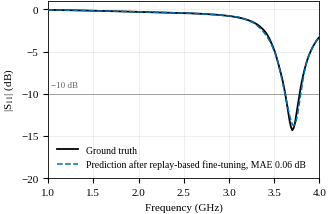

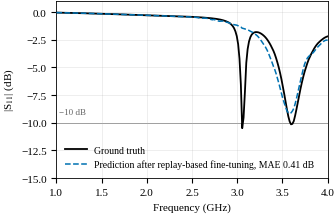

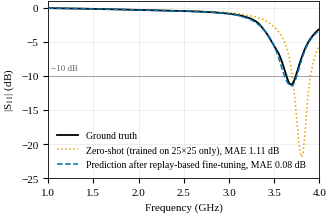

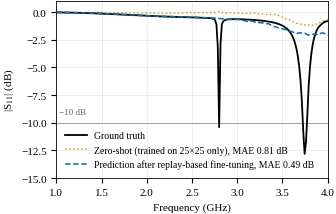

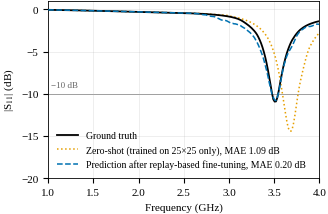

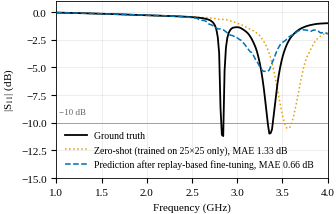

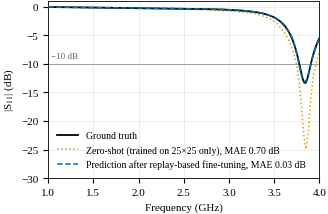

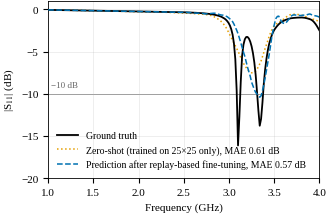

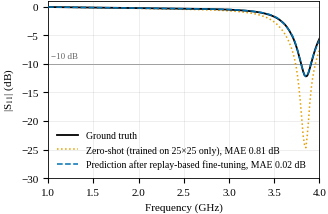

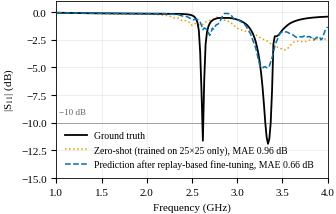

10 figures written to /content/drive/MyDrive/antenna_gnn/figures/ch46: ['ch46_25x25_single_band', 'ch46_25x25_dual_band', 'ch46_12x12_single_band', 'ch46_12x12_dual_band', 'ch46_15x15_single_band', 'ch46_15x15_dual_band', 'ch46_35x35_single_band', 'ch46_35x35_dual_band', 'ch46_45x45_single_band', 'ch46_45x45_dual_band']


In [ ]:
# ── The figures: 2 for 25x25 (truth + fine-tuned), 2 for each of 12/15/35/45 (truth + zero-shot + fine-tuned) ──
W, H = 3.5, 2.3
MADE = []
for r in SEL.itertuples():
    N = r.grid; T, Pf, Pz = RES[N]; j = r.row
    fig, ax = plt.subplots(figsize=(W, H))
    ax.axhline(TAU, color='0.55', lw=0.6, ls='-', zorder=0)
    ax.text(1.03, TAU + 0.6, '−10 dB', ha='left', va='bottom', fontsize=6.5, color='0.4')
    ax.plot(F, T[j], **STYLE['gt'], zorder=3)
    if N != 25:
        ax.plot(F, Pz[j], **{**STYLE['zs'], 'label': f'{STYLE["zs"]["label"]}, MAE {r.mae_zs:.2f} dB'}, zorder=2)
    ax.plot(F, Pf[j], **{**STYLE['ft'], 'label': f'{STYLE["ft"]["label"]}, MAE {r.mae_ft:.2f} dB'}, zorder=4)
    lo = min(T[j].min(), Pf[j].min(), Pz[j].min() if N != 25 else 0)
    ax.set_xlim(1, 4); ax.set_ylim(np.floor((lo - 2) / 5) * 5, 1)
    ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('|S$_{11}$| (dB)')
    # keep the legend clear of the curves: lower left unless a dip below -15 dB falls in 1.0-2.3 GHz, then lower right
    low = F < 2.3
    curves = [T[j], Pf[j]] + ([Pz[j]] if N != 25 else [])
    loc = 'lower right' if any(c[low].min() < -15 for c in curves) else 'lower left'
    ax.legend(frameon=False, loc=loc, handlelength=2.2)
    stem = f'ch46_{N}x{N}_{r.band}_band'
    for ext in ('pdf', 'png'):
        fig.savefig(f'{FIG}/{stem}.{ext}', dpi=600 if ext == 'png' else None)
    plt.show(); plt.close(fig); MADE.append(stem)
print(f'{len(MADE)} figures written to {FIG}:', MADE)

## 8. Captions and guards
**Writes:** `ch46_captions.md`, with a draft caption per figure that labels it best-case and gives its errors alongside the group median.

**Guards:**
- all 10 figures exist as PDF and PNG
- fonts are embedded
- no 55×55
- no earlier artifact or checkpoint was modified

In [ ]:
# ── Captions, manifest, guards ──
cap = ['# Chunk 46 — S11 prediction figures: draft captions', '',
       f'Fine-tuned model: `{Path(MODEL_FT).name}` (one replay-fine-tuned GNN for 12/15/25/35/45). Zero-shot model: '
       '`best_model.pt` (trained on 25×25 only). Each figure shows the test antenna with the most accurate fine-tuned '
       f'prediction (lowest {SELECT_METRIC.upper()}) for its grid and band type: a best-case example. Bands are true-curve dips '
       'below −10 dB with ≥ 3 dB prominence, ≥ 150 MHz apart. Each caption also gives the median error of that group, '
       'so the typical case is stated alongside the best one.', '']
for r in SEL.itertuples():
    base = (f'**{r.grid}×{r.grid}, {r.band} band** (`ch46_{r.grid}x{r.grid}_{r.band}_band`). Simulated and predicted |S11| for the '
            f'{r.grid}×{r.grid} test antenna with {"one band" if r.band == "single" else "two bands"} (true dips at {r.true_dips_ghz} GHz) '
            f'whose fine-tuned prediction is the most accurate of {r.group_size} such test antennas. ')
    if r.grid == 25:
        base += f'Replay-fine-tuned GNN: MAE {r.mae_ft:.2f} dB, MSE {r.mse_ft:.2f} dB².'
    else:
        base += (f'Zero-shot (25×25-trained) model: MAE {r.mae_zs:.2f} dB, MSE {r.mse_zs:.2f} dB²; after replay-based fine-tuning: '
                 f'MAE {r.mae_ft:.2f} dB, MSE {r.mse_ft:.2f} dB².')
    base += f' Median over the group after fine-tuning: MAE {r.group_median_mae_ft:.2f} dB, MSE {r.group_median_mse_ft:.2f} dB².'
    cap += [base, '']
open(OUT('ch46_captions.md'), 'w').write('\n'.join(cap) + '\n'); print('\n'.join(cap))

fails = []
def guard(ok, msg):
    print(f"  [{'PASS' if ok else 'FAIL'}] {msg}")
    if not ok: fails.append(msg)
expected = [f'ch46_{N}x{N}_{b}_band' for N in GRIDS for b in ('single', 'dual')]
guard(set(MADE) == set(expected), f'{len(MADE)} of 10 figures produced' + ('' if set(MADE) == set(expected) else f'; missing {sorted(set(expected) - set(MADE))}'))
guard(all(os.path.exists(f'{FIG}/{s}.pdf') and os.path.exists(f'{FIG}/{s}.png') for s in MADE), 'every figure saved as PDF and PNG')
guard(all(b'/FontFile' in open(f'{FIG}/{s}.pdf', 'rb').read() for s in MADE), 'fonts embedded in every PDF')
guard(not any(SEL.grid == 55), 'no 55x55')
guard(all(os.path.getmtime(p) == t for p, t in PRIOR.items() if os.path.exists(p)), f'no earlier artifact or checkpoint modified ({len(PRIOR)})')
assert not fails, fails
print('ALL GUARDS PASSED. No training; test predictions used for illustration only.')

# Chunk 46 — S11 prediction figures: draft captions

Fine-tuned model: `ch44_ft15_from4_replay_p100_s0.pt` (one replay-fine-tuned GNN for 12/15/25/35/45). Zero-shot model: `best_model.pt` (trained on 25×25 only). Each figure shows the test antenna with the most accurate fine-tuned prediction (lowest MSE) for its grid and band type: a best-case example. Bands are true-curve dips below −10 dB with ≥ 3 dB prominence, ≥ 150 MHz apart. Each caption also gives the median error of that group, so the typical case is stated alongside the best one.

**25×25, single band** (`ch46_25x25_single_band`). Simulated and predicted |S11| for the 25×25 test antenna with one band (true dips at 3.70 GHz) whose fine-tuned prediction is the most accurate of 5136 such test antennas. Replay-fine-tuned GNN: MAE 0.06 dB, MSE 0.03 dB². Median over the group after fine-tuning: MAE 0.31 dB, MSE 1.03 dB².

**25×25, dual band** (`ch46_25x25_dual_band`). Simulated and predicted |S11| for the 25×25 test antenna with two